# Math 465 Fall 2026

## Module 6. Demo: Gradient descent on quadratic objectives

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu


This notebook demonstrates:

- gradient descent as an iterative method for minimizing a strongly convex quadratic;
- how the eigenvalues and condition number of the Hessian affect the trajectory and convergence rate;
- how the step size determines stability.

We compare two-dimensional examples with the same minimizer and starting point, but very different condition numbers.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)


### Example. Gradient descent on quadratic objectives

Consider

$$f(x)=\frac12 x^T A x-b^T x,\qquad A=A^T\succ0.$$

Then $\nabla f(x)=Ax-b$, and the unique minimizer $x^*$ solves $Ax^*=b$. Gradient descent with step size $\eta$ obeys

$$x_{k+1}=x_k-\eta(Ax_k-b),\qquad e_{k+1}=(I-\eta A)e_k,$$

where $e_k=x_k-x^*$. In an eigenvector direction of $A$ with eigenvalue $\lambda_i$, the error is multiplied by $1-\eta\lambda_i$ at each step.


#### Helper functions


In [2]:
def quadratic_value(x, A, b):
    return 0.5 * x @ A @ x - b @ x


def quadratic_grad(x, A, b):
    return A @ x - b


def gradient_descent(A, b, x0, eta, n_steps):
    x = np.array(x0, dtype=float)
    xs = [x.copy()]
    fs = [quadratic_value(x, A, b)]
    for _ in range(n_steps):
        x = x - eta * quadratic_grad(x, A, b)
        xs.append(x.copy())
        fs.append(quadratic_value(x, A, b))
    return np.array(xs), np.array(fs)


def quadratic_summary(A):
    eigvals = np.linalg.eigvalsh(A)
    mu, L = eigvals.min(), eigvals.max()
    return eigvals, mu, L, L / mu


def contour_with_trajectory(A, xs, x_star, title, gap_max):
    # Plot objective gaps directly, so both examples use meaningful, log-spaced levels.
    pad = 0.35
    x_min = min(-2.5, xs[:, 0].min() - pad, x_star[0] - pad)
    x_max = max( 2.5, xs[:, 0].max() + pad, x_star[0] + pad)
    y_min = min(-2.5, xs[:, 1].min() - pad, x_star[1] - pad)
    y_max = max( 2.5, xs[:, 1].max() + pad, x_star[1] + pad)
    u = np.linspace(x_min, x_max, 400)
    v = np.linspace(y_min, y_max, 400)
    U, V = np.meshgrid(u, v)
    D0, D1 = U - x_star[0], V - x_star[1]
    G = 0.5 * (A[0, 0] * D0**2 + 2 * A[0, 1] * D0 * D1 + A[1, 1] * D1**2)
    levels = np.geomspace(1e-3, gap_max, 22)

    fig, ax = plt.subplots(figsize=(4.0, 3.2), constrained_layout=True)
    contours = ax.contour(U, V, G, levels=levels, cmap='Blues', linewidths=0.9)
    ax.plot(xs[:, 0], xs[:, 1], color='#d1495b', linewidth=1.8, zorder=3, label='GD path')
    stride = max(1, len(xs) // 12)
    ax.scatter(xs[::stride, 0], xs[::stride, 1], s=22, color='#d1495b', edgecolor='white', linewidth=0.5, zorder=4, label='Iterates')
    ax.scatter(*xs[0], marker='o', s=75, color='#00798c', edgecolor='white', linewidth=0.8, zorder=5, label='Start')
    ax.scatter(*xs[-1], marker='X', s=90, color='#d1495b', edgecolor='white', linewidth=0.8, zorder=5, label='Last shown iterate')
    ax.scatter(*x_star, marker='*', s=170, color='#edae49', edgecolor='#333333', linewidth=0.7, zorder=6, label=r'$x^*$')
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_title(title)
    ax.set_aspect('equal', adjustable='box')
    ax.legend(frameon=True, fontsize=8, loc='best')
    plt.show()


def plot_objective_gap(fs, f_star, title, label=None):
    gaps = fs - f_star
    gaps = np.where(gaps > 0, gaps, np.nan)  # avoid plotting an artificial numerical floor
    k = np.arange(len(gaps))
    fig, ax = plt.subplots(figsize=(4.4, 2.6), constrained_layout=True)
    ax.semilogy(k, gaps, linewidth=2, label=label)
    ax.set_xlabel(r'iteration $k$')
    ax.set_ylabel(r'$f(x_k)-f(x^*)$')
    ax.set_title(title)
    if label:
        ax.legend(frameon=False)
    ax.grid(True, which='both', alpha=0.25)
    plt.show()


#### Case 1. Well-conditioned quadratic

Take $A=\operatorname{diag}(1,2)$, so its condition number is $\kappa=2$. We set $x^*=(1,1)^T$, hence $b=Ax^*$, and start from $x_0=(-2,2.5)^T$. The step size $\eta=1/L$ is chosen using the largest eigenvalue.


In [3]:
x_star = np.array([1.0, 1.0])
x0 = np.array([-2.0, 2.5])

A_good = np.diag([1.0, 2.0])
b_good = A_good @ x_star
eigvals, mu, L, kappa = quadratic_summary(A_good)
eta_good = 1.0 / L
xs_good, fs_good = gradient_descent(A_good, b_good, x0, eta_good, n_steps=20)
f_star_good = quadratic_value(x_star, A_good, b_good)

print(f'eigenvalues: {eigvals}; mu={mu:g}, L={L:g}, condition number={kappa:g}')
print(f'eta={eta_good:g}; final iterate={xs_good[-1]}; distance to x*={np.linalg.norm(xs_good[-1] - x_star):.3e}')


eigenvalues: [1. 2.]; mu=1, L=2, condition number=2
eta=0.5; final iterate=[1. 1.]; distance to x*=2.861e-06


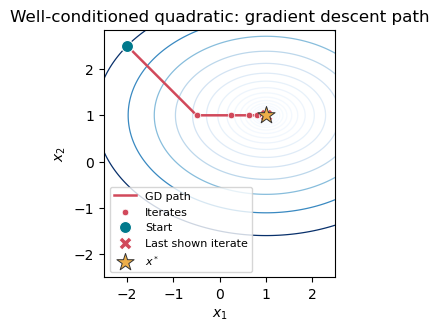

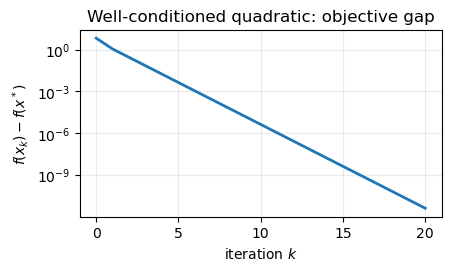

In [4]:
contour_with_trajectory(
    A_good, xs_good, x_star,
    'Well-conditioned quadratic: gradient descent path',
    gap_max=quadratic_value(x0, A_good, b_good) - f_star_good,
)
plot_objective_gap(fs_good, f_star_good, 'Well-conditioned quadratic: objective gap')


With $\eta=1/L=1/2$, the error contraction factors are $1/2$ and $0$. The component in the higher-curvature direction disappears in one step; the other component then halves at each step.


#### Case 2. Ill-conditioned quadratic

Now take $A=\operatorname{diag}(1,100)$, whose condition number is $\kappa=100$. We keep the same $x^*$ and $x_0$, and again use $\eta=1/L$. This small step is needed to control the direction with curvature 100.


In [5]:
A_bad = np.diag([1.0, 100.0])
b_bad = A_bad @ x_star
eigvals, mu, L, kappa = quadratic_summary(A_bad)
eta_bad = 1.0 / L
xs_bad, fs_bad = gradient_descent(A_bad, b_bad, x0, eta_bad, n_steps=500)
f_star_bad = quadratic_value(x_star, A_bad, b_bad)

print(f'eigenvalues: {eigvals}; mu={mu:g}, L={L:g}, condition number={kappa:g}')
print(f'eta={eta_bad:g}; final iterate={xs_bad[-1]}; distance to x*={np.linalg.norm(xs_bad[-1] - x_star):.3e}')


eigenvalues: [  1. 100.]; mu=1, L=100, condition number=100
eta=0.01; final iterate=[0.9803 1.    ]; distance to x*=1.971e-02


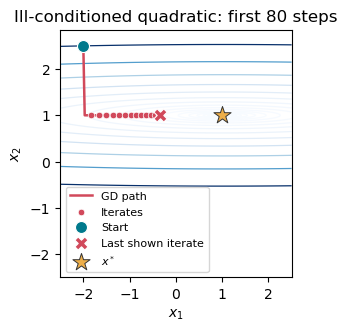

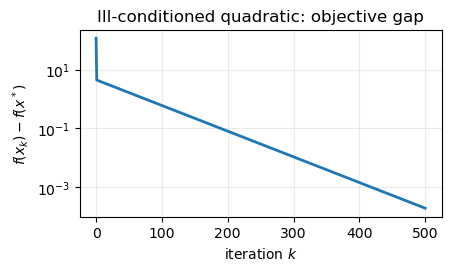

In [6]:
contour_with_trajectory(
    A_bad, xs_bad[:81], x_star,
    'Ill-conditioned quadratic: first 80 steps',
    gap_max=quadratic_value(x0, A_bad, b_bad) - f_star_bad,
)
plot_objective_gap(fs_bad, f_star_bad, 'Ill-conditioned quadratic: objective gap')


Here the contraction factors are $0$ in the $\lambda=100$ direction and $0.99$ in the $\lambda=1$ direction. The steep direction is corrected immediately, but progress along the shallow direction is slow. The narrow, elongated contours make this imbalance visible: a step size small enough for the steep direction makes only small progress along the shallow one.


#### Compare the convergence rates


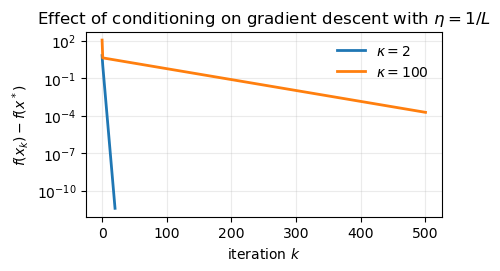

In [7]:
fig, ax = plt.subplots(figsize=(4.4, 2.6), constrained_layout=True)
for gaps, label in [(fs_good - f_star_good, r'$\kappa=2$'), (fs_bad - f_star_bad, r'$\kappa=100$')]:
    gaps = np.where(gaps > 0, gaps, np.nan)
    ax.semilogy(np.arange(len(gaps)), gaps, linewidth=2, label=label)
ax.set_xlabel(r'iteration $k$')
ax.set_ylabel(r'$f(x_k)-f(x^*)$')
ax.set_title(r'Effect of conditioning on gradient descent with $\eta=1/L$')
ax.grid(True, which='both', alpha=0.25)
ax.legend(frameon=False)
plt.show()


The ill-conditioned problem needs many more iterations because the step size is restricted by its largest eigenvalue, while the slow direction is governed by the much smaller eigenvalue. This difference is summarized by $\kappa=L/\mu$.


#### Optional. What if the step size is too large?

For a quadratic with $A\succ0$, convergence requires $|1-\eta\lambda_i|<1$ for every eigenvalue, or $0<\eta<2/L$. The boundary value $2/L$ does not contract the largest-eigenvalue direction; a larger step makes that direction diverge.


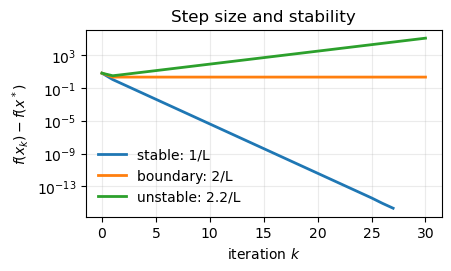

In [8]:
L_good = np.linalg.eigvalsh(A_good).max()
etas = {
    'stable: 1/L': 1.0 / L_good,
    'boundary: 2/L': 2.0 / L_good,
    'unstable: 2.2/L': 2.2 / L_good,
}

fig, ax = plt.subplots(figsize=(4.4, 2.6), constrained_layout=True)
for label, eta in etas.items():
    _, fs = gradient_descent(A_good, b_good, x0, eta, n_steps=30)
    gaps = np.where(fs - f_star_good > 0, fs - f_star_good, np.nan)
    ax.semilogy(np.arange(len(gaps)), gaps, linewidth=2, label=label)
ax.set_xlabel(r'iteration $k$')
ax.set_ylabel(r'$f(x_k)-f(x^*)$')
ax.set_title('Step size and stability')
ax.grid(True, which='both', alpha=0.25)
ax.legend(frameon=False)
plt.show()


### Takeaway

For $f(x)=\frac12x^TAx-b^Tx$ with $A\succ0$, the minimizer is the unique solution of $Ax=b$, and gradient descent is an iterative linear solver. The largest eigenvalue sets the step-size scale; the ratio $L/\mu$ describes how unevenly the method progresses across directions. A large condition number leads to slow convergence when using a step size small enough to remain stable in every direction.
